## 1. Instalasi dan import library

In [1]:
# Jika diperlukan, jalankan instalasi ini.
# Di Google Colab sebagian besar paket biasanya sudah tersedia.
!pip -q install torch torchvision scikit-learn matplotlib seaborn pandas pillow

In [2]:
import os
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import EMNIST
from torchvision import transforms

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.14.1+cpu


## 2. Konfigurasi eksperimen

In [3]:
# Parameter dapat diubah sesuai kemampuan perangkat.
DATA_ROOT = "./data"
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

N_SPLITS = 5
CV_MAX_SAMPLES = 25000   # subset stratified untuk 5-fold CV agar waktu komputasi terjangkau
EPOCHS_CV = 5
EPOCHS_FINAL = 10
PATIENCE = 3

NUM_CLASSES = 10
INPUT_SIZE = 28 * 28

# EMNIST disimpan dengan orientasi yang perlu ditransposisikan agar tegak.
# Jika visualisasi sampel sudah tegak pada perangkat/dataset yang digunakan,
# ubah menjadi False.
FIX_EMNIST_ORIENTATION = True

## 3. Memuat dataset EMNIST Digits

In [4]:
# EMNIST Digits memiliki 10 kelas (angka 0 sampai 9).
# torchvision akan mengunduh file dataset secara otomatis pada pemanggilan pertama.
train_dataset = EMNIST(
    root=DATA_ROOT, split="digits", train=True, download=True,
    transform=transforms.ToTensor()
)
test_dataset = EMNIST(
    root=DATA_ROOT, split="digits", train=False, download=True,
    transform=transforms.ToTensor()
)

print("Jumlah data latih :", len(train_dataset))
print("Jumlah data uji   :", len(test_dataset))
print("Kelas             :", train_dataset.classes if hasattr(train_dataset, "classes") else list(range(10)))

100%|██████████| 562M/562M [00:07<00:00, 79.0MB/s]


Jumlah data latih : 240000
Jumlah data uji   : 40000
Kelas             : ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


## 4. Menyiapkan array dan preprocessing

In [5]:
def dataset_to_numpy(dataset, fix_orientation=True):
    images = dataset.data.cpu().numpy() if torch.is_tensor(dataset.data) else np.asarray(dataset.data)
    labels = dataset.targets.cpu().numpy() if torch.is_tensor(dataset.targets) else np.asarray(dataset.targets)

    # Bentuk citra menjadi (N, 28, 28).
    images = images.reshape(-1, 28, 28)

    # EMNIST pada format IDX memiliki orientasi kolom/baris yang berbeda.
    # Transpose dua sumbu spasial untuk menampilkan karakter dengan orientasi normal.
    if fix_orientation:
        images = np.transpose(images, (0, 2, 1))

    # Normalisasi intensitas piksel dari [0, 255] ke [0, 1].
    images = images.astype(np.float32) / 255.0

    # MLP menerima vektor 784 fitur per gambar.
    images = images.reshape(len(images), 784)
    labels = labels.astype(np.int64)
    return images, labels

X_train_all, y_train_all = dataset_to_numpy(train_dataset, FIX_EMNIST_ORIENTATION)
X_test, y_test = dataset_to_numpy(test_dataset, FIX_EMNIST_ORIENTATION)

print("X_train:", X_train_all.shape, "| y_train:", y_train_all.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)
print("Rentang piksel:", X_train_all.min(), "s.d.", X_train_all.max())
print("Label unik:", np.unique(y_train_all))

X_train: (240000, 784) | y_train: (240000,)
X_test : (40000, 784) | y_test : (40000,)
Rentang piksel: 0.0 s.d. 1.0
Label unik: [0 1 2 3 4 5 6 7 8 9]


## 5. Exploratory Data Analysis (EDA)

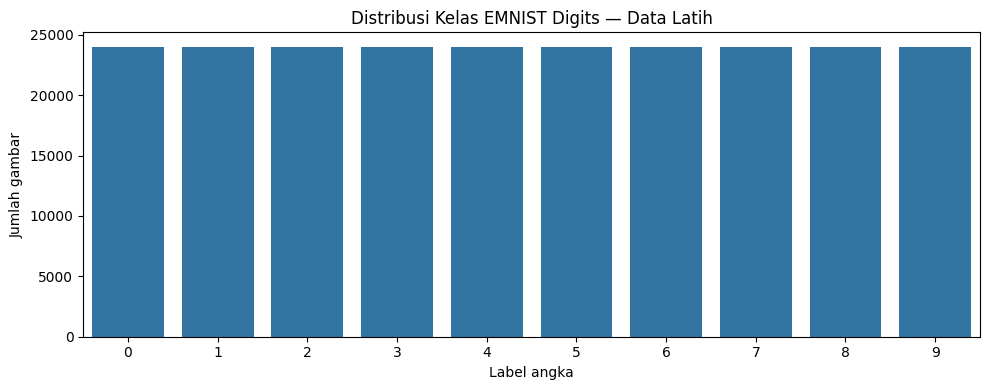

   jumlah_data
0        24000
1        24000
2        24000
3        24000
4        24000
5        24000
6        24000
7        24000
8        24000
9        24000


In [6]:
# Distribusi kelas pada data latih
class_counts = pd.Series(y_train_all).value_counts().sort_index()
plt.figure(figsize=(10, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Distribusi Kelas EMNIST Digits — Data Latih")
plt.xlabel("Label angka")
plt.ylabel("Jumlah gambar")
plt.xticks(range(10))
plt.tight_layout()
plt.show()

print(class_counts.to_frame("jumlah_data"))

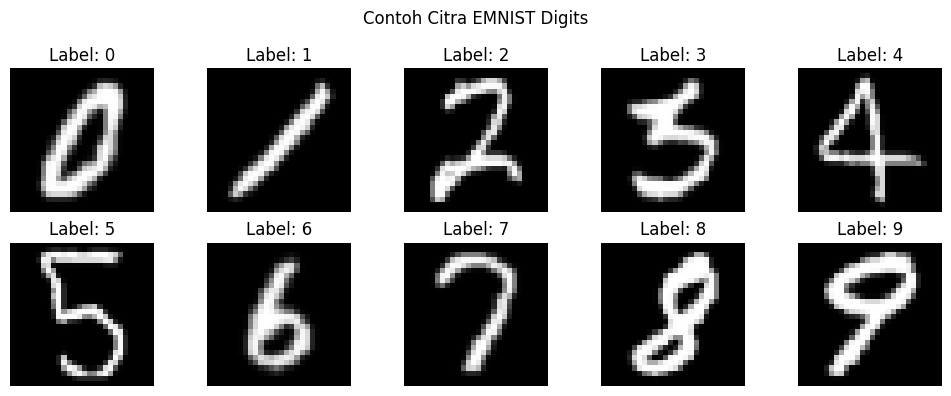

In [7]:
# Contoh citra angka. Tampilan ini juga membantu memeriksa orientasi dataset.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    idx = np.where(y_train_all == digit)[0][0]
    ax.imshow(X_train_all[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")
plt.suptitle("Contoh Citra EMNIST Digits")
plt.tight_layout()
plt.show()

## 6. Membagi data validasi dan menyiapkan tensor

In [8]:
# Data uji resmi EMNIST disimpan terpisah dan tidak digunakan saat cross-validation.
# Untuk evaluasi final, data uji hanya digunakan setelah model selesai dilatih.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all,
    test_size=0.10, random_state=SEED, stratify=y_train_all
)

def to_tensor_dataset(X, y):
    return TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Train: (216000, 784) Validation: (24000, 784) Test: (40000, 784)


## 7. Desain arsitektur MLP

Model yang digunakan memiliki arsitektur:

\[
784 \rightarrow 256 \rightarrow 128 \rightarrow 10
\]

- **Input layer:** 784 neuron, berasal dari citra 28 × 28 piksel yang diratakan (*flatten*).
- **Hidden layer 1:** 256 neuron dengan aktivasi ReLU.
- **Hidden layer 2:** 128 neuron dengan aktivasi ReLU.
- **Output layer:** 10 neuron, satu untuk setiap kelas angka 0–9.

Dimensi parameter:
- \(W_1: 256 \times 784\), \(b_1: 256\)
- \(W_2: 128 \times 256\), \(b_2: 128\)
- \(W_3: 10 \times 128\), \(b_3: 10\)

Softmax tidak ditulis di dalam model karena `CrossEntropyLoss` di PyTorch sudah menggabungkan operasi log-softmax dan negative log-likelihood.

In [9]:
class MLP(nn.Module):
    def __init__(self, input_size=784, num_classes=10):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

model_example = MLP().to(DEVICE)
print(model_example)

print("\\nDimensi bobot dan bias:")
for name, param in model_example.named_parameters():
    print(f"{name:25s} {tuple(param.shape)}")

total_params = sum(p.numel() for p in model_example.parameters())
print("\\nTotal parameter:", total_params)

MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
\nDimensi bobot dan bias:
network.0.weight          (256, 784)
network.0.bias            (256,)
network.2.weight          (128, 256)
network.2.bias            (128,)
network.4.weight          (10, 128)
network.4.bias            (10,)
\nTotal parameter: 235146


## 8. Fungsi training dan evaluasi

In [10]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    all_preds, all_targets = [], []

    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(yb.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    return avg_loss, acc


def train_model(model, train_loader, val_loader, epochs, patience=PATIENCE):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    wait = 0

    for epoch in range(1, epochs + 1):
        start = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={tr_loss:.4f} | val_loss={va_loss:.4f} | "
            f"train_acc={tr_acc:.4f} | val_acc={va_acc:.4f} | "
            f"{time.time()-start:.1f}s"
        )

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_state)
    return model, history


def plot_history(history, title="Kurva Training"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 9. Stratified 5-Fold Cross Validation

Cross-validation dilakukan pada bagian data latih (bukan data uji resmi). `StratifiedKFold` menjaga proporsi kelas pada setiap fold. Agar komputasi lebih terjangkau, secara default digunakan subset stratified maksimal 25.000 sampel. Ubah `CV_MAX_SAMPLES = None` jika ingin menggunakan seluruh data latih dan perangkat memadai.

In [11]:
if CV_MAX_SAMPLES is None or CV_MAX_SAMPLES >= len(X_train):
    X_cv, y_cv = X_train, y_train
else:
    X_cv, _, y_cv, _ = train_test_split(
        X_train, y_train,
        train_size=CV_MAX_SAMPLES,
        random_state=SEED,
        stratify=y_train
    )

print("Jumlah sampel untuk CV:", len(X_cv))
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

cv_rows = []
cv_histories = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), start=1):
    print(f"\\n========== FOLD {fold}/{N_SPLITS} ==========")

    fold_train_ds = to_tensor_dataset(X_cv[train_idx], y_cv[train_idx])
    fold_val_ds = to_tensor_dataset(X_cv[val_idx], y_cv[val_idx])

    fold_train_loader = DataLoader(
        fold_train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=0, pin_memory=(DEVICE.type == "cuda")
    )
    fold_val_loader = DataLoader(
        fold_val_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=0, pin_memory=(DEVICE.type == "cuda")
    )

    fold_model = MLP().to(DEVICE)
    start_time = time.time()
    fold_model, fold_history = train_model(
        fold_model, fold_train_loader, fold_val_loader, EPOCHS_CV
    )
    elapsed = time.time() - start_time
    cv_histories.append(fold_history)

    criterion = nn.CrossEntropyLoss()
    val_loss, _ = run_epoch(fold_model, fold_val_loader, criterion)

    fold_model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in fold_val_loader:
            logits = fold_model(xb.to(DEVICE))
            preds.extend(logits.argmax(1).cpu().numpy())
            targets.extend(yb.numpy())

    cv_rows.append({
        "fold": fold,
        "accuracy": accuracy_score(targets, preds),
        "precision_macro": precision_score(targets, preds, average="macro", zero_division=0),
        "recall_macro": recall_score(targets, preds, average="macro", zero_division=0),
        "f1_macro": f1_score(targets, preds, average="macro", zero_division=0),
        "validation_loss": val_loss,
        "training_time_seconds": elapsed
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results)
print("\\nRata-rata dan standar deviasi:")
display(cv_results.drop(columns="fold").agg(["mean", "std"]))

Jumlah sampel untuk CV: 25000
\n========== FOLD 1/5 ==========
Epoch 01/5 | train_loss=0.7201 | val_loss=0.2831 | train_acc=0.8269 | val_acc=0.9190 | 1.1s
Epoch 02/5 | train_loss=0.2359 | val_loss=0.2382 | train_acc=0.9355 | val_acc=0.9280 | 0.7s
Epoch 03/5 | train_loss=0.1828 | val_loss=0.1832 | train_acc=0.9489 | val_acc=0.9478 | 0.7s
Epoch 04/5 | train_loss=0.1460 | val_loss=0.1708 | train_acc=0.9588 | val_acc=0.9526 | 0.6s
Epoch 05/5 | train_loss=0.1240 | val_loss=0.1453 | train_acc=0.9647 | val_acc=0.9594 | 1.0s
\n========== FOLD 2/5 ==========
Epoch 01/5 | train_loss=0.7179 | val_loss=0.2922 | train_acc=0.8160 | val_acc=0.9204 | 1.0s
Epoch 02/5 | train_loss=0.2387 | val_loss=0.2397 | train_acc=0.9325 | val_acc=0.9340 | 0.9s
Epoch 03/5 | train_loss=0.1850 | val_loss=0.2024 | train_acc=0.9476 | val_acc=0.9436 | 0.7s
Epoch 04/5 | train_loss=0.1513 | val_loss=0.1700 | train_acc=0.9569 | val_acc=0.9544 | 0.7s
Epoch 05/5 | train_loss=0.1267 | val_loss=0.1662 | train_acc=0.9645 | val_ac

,fold,accuracy,precision_macro,recall_macro,f1_macro,validation_loss,training_time_seconds
0,1,0.9594,0.959625,0.9594,0.959412,0.145275,4.150856
1,2,0.9514,0.952346,0.9514,0.951488,0.166246,3.943764
2,3,0.9658,0.966198,0.9658,0.965875,0.121227,3.316892
3,4,0.9580,0.958369,0.9580,0.957945,0.154195,4.636548
4,5,0.9570,0.957210,0.9570,0.956972,0.155093,4.063293


\nRata-rata dan standar deviasi:


,accuracy,precision_macro,recall_macro,f1_macro,validation_loss,training_time_seconds
mean,0.958320,0.958750,0.958320,0.958338,0.148407,4.022271
std,0.005168,0.004994,0.005168,0.005170,0.016919,0.474151


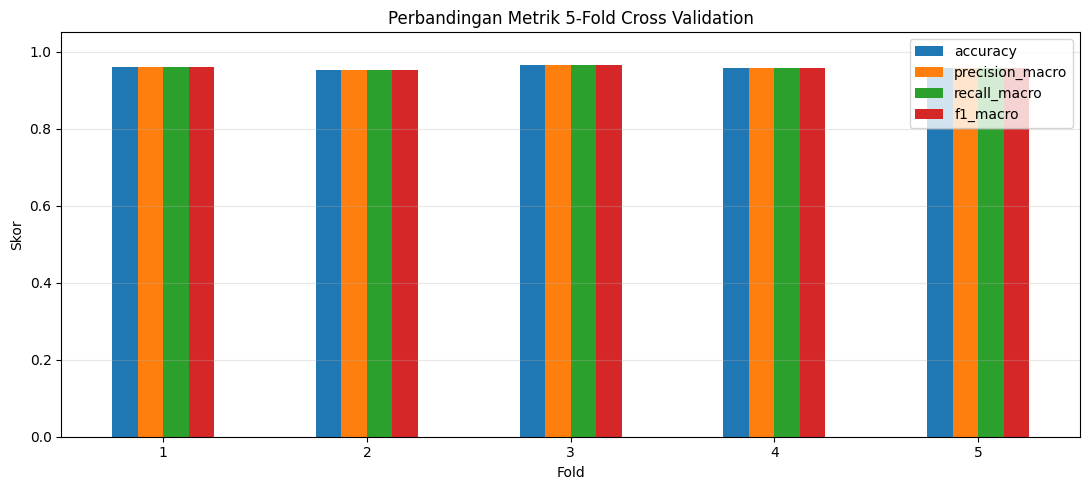

Disimpan: emnist_mlp_cv_results.csv


In [12]:
# Visualisasi perbandingan metrik antar-fold
metric_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
cv_results.set_index("fold")[metric_cols].plot(kind="bar", figsize=(11, 5))
plt.title("Perbandingan Metrik 5-Fold Cross Validation")
plt.xlabel("Fold")
plt.ylabel("Skor")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

cv_results.to_csv("emnist_mlp_cv_results.csv", index=False)
print("Disimpan: emnist_mlp_cv_results.csv")

## 10. Melatih model final

Setelah cross-validation, model final dilatih pada seluruh data latih yang disediakan EMNIST. Sebagian kecil data latih dipisahkan sebagai validation untuk memantau overfitting dan early stopping. Data uji resmi tetap tidak disentuh sampai evaluasi final.

Epoch 01/10 | train_loss=0.1906 | val_loss=0.0820 | train_acc=0.9475 | val_acc=0.9772 | 7.4s
Epoch 02/10 | train_loss=0.0663 | val_loss=0.0579 | train_acc=0.9807 | val_acc=0.9835 | 8.7s
Epoch 03/10 | train_loss=0.0493 | val_loss=0.0509 | train_acc=0.9853 | val_acc=0.9855 | 13.0s
Epoch 04/10 | train_loss=0.0417 | val_loss=0.0454 | train_acc=0.9876 | val_acc=0.9870 | 16.9s
Epoch 05/10 | train_loss=0.0363 | val_loss=0.0525 | train_acc=0.9892 | val_acc=0.9855 | 20.2s
Epoch 06/10 | train_loss=0.0330 | val_loss=0.0429 | train_acc=0.9901 | val_acc=0.9869 | 27.2s
Epoch 07/10 | train_loss=0.0302 | val_loss=0.0418 | train_acc=0.9909 | val_acc=0.9884 | 35.8s
Epoch 08/10 | train_loss=0.0284 | val_loss=0.0385 | train_acc=0.9916 | val_acc=0.9892 | 31.9s
Epoch 09/10 | train_loss=0.0264 | val_loss=0.0396 | train_acc=0.9920 | val_acc=0.9878 | 25.1s
Epoch 10/10 | train_loss=0.0254 | val_loss=0.0412 | train_acc=0.9924 | val_acc=0.9879 | 18.8s


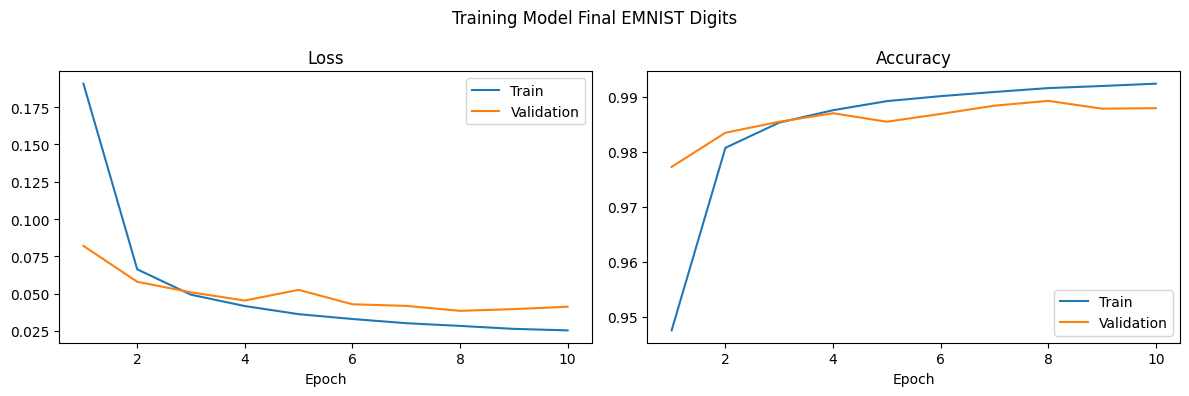

In [13]:
X_final_train, X_final_val, y_final_train, y_final_val = train_test_split(
    X_train_all, y_train_all,
    test_size=0.10, random_state=SEED, stratify=y_train_all
)

final_train_loader = DataLoader(
    to_tensor_dataset(X_final_train, y_final_train),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)
final_val_loader = DataLoader(
    to_tensor_dataset(X_final_val, y_final_val),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

final_model = MLP().to(DEVICE)
final_model, final_history = train_model(
    final_model, final_train_loader, final_val_loader, EPOCHS_FINAL
)
plot_history(final_history, "Training Model Final EMNIST Digits")

## 11. Evaluasi pada data uji resmi

In [14]:
test_loader = DataLoader(
    to_tensor_dataset(X_test, y_test),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

final_model.eval()
y_pred, y_true = [], []
test_start = time.time()
with torch.no_grad():
    for xb, yb in test_loader:
        logits = final_model(xb.to(DEVICE))
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(yb.numpy())
test_duration = time.time() - test_start

test_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "inference_time_seconds": test_duration
}
test_metrics_df = pd.DataFrame([test_metrics])
display(test_metrics_df)

print(classification_report(
    y_true, y_pred, labels=list(range(10)), zero_division=0
))

,accuracy,precision_macro,recall_macro,f1_macro,inference_time_seconds
0,0.98775,0.987814,0.98775,0.987758,3.673168


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4000
           1       0.99      1.00      0.99      4000
           2       0.99      0.99      0.99      4000
           3       0.98      0.98      0.98      4000
           4       0.99      0.99      0.99      4000
           5       0.99      0.98      0.98      4000
           6       0.99      0.99      0.99      4000
           7       0.99      0.99      0.99      4000
           8       0.97      0.99      0.98      4000
           9       0.99      0.98      0.99      4000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000



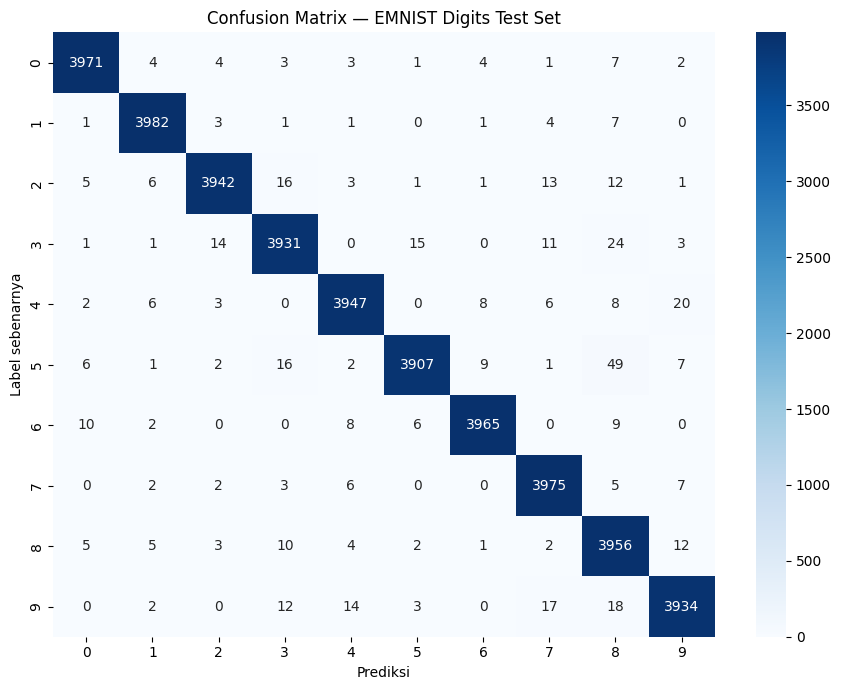

In [15]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.title("Confusion Matrix — EMNIST Digits Test Set")
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.tight_layout()
plt.show()

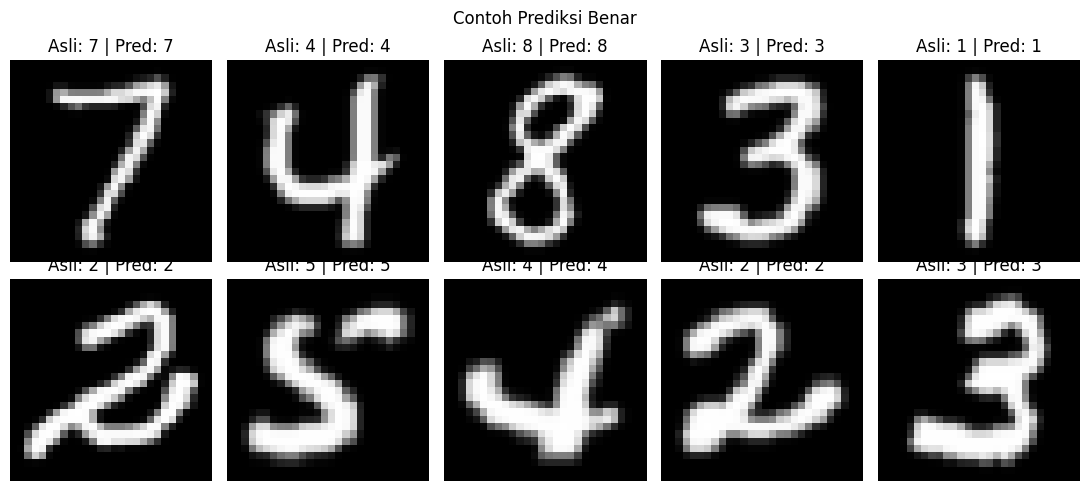

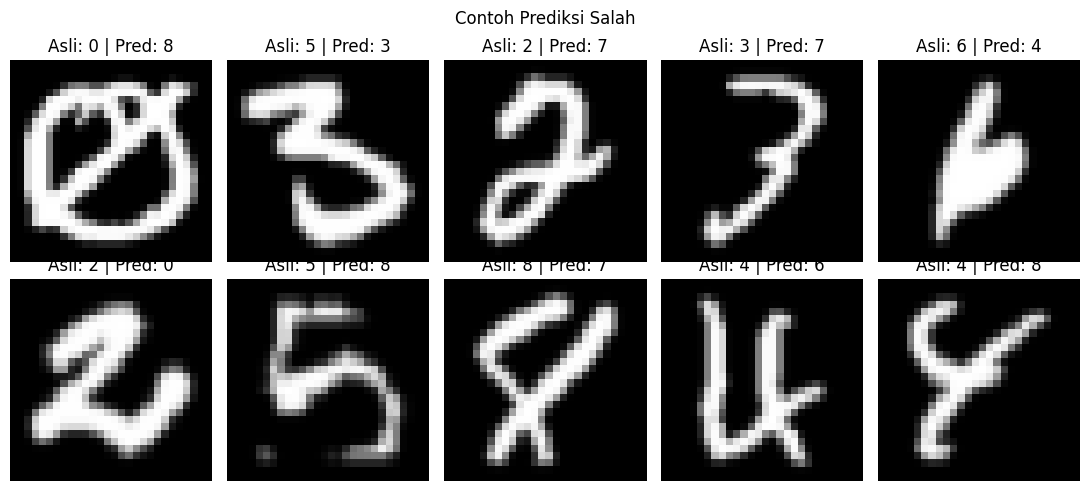

In [16]:
# Contoh prediksi benar dan salah
wrong_indices = np.where(np.array(y_pred) != np.array(y_true))[0]
correct_indices = np.where(np.array(y_pred) == np.array(y_true))[0]

def show_predictions(indices, title, count=10):
    if len(indices) == 0:
        print("Tidak ada sampel untuk ditampilkan.")
        return
    chosen = np.random.choice(indices, size=min(count, len(indices)), replace=False)
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))
    for ax, idx in zip(axes.flat, chosen):
        ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
        ax.set_title(f"Asli: {y_test[idx]} | Pred: {y_pred[idx]}")
        ax.axis("off")
    for ax in axes.flat[len(chosen):]:
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_predictions(correct_indices, "Contoh Prediksi Benar")
show_predictions(wrong_indices, "Contoh Prediksi Salah")

## 12. Fungsi prediksi satu gambar

Fungsi berikut menerima gambar 28×28 dalam bentuk array grayscale bernilai 0–255 atau 0–1. Untuk hasil terbaik, gambar sebaiknya berisi satu angka, latar belakang gelap dan goresan terang seperti citra EMNIST. Jika gambar berasal dari foto kertas, perlu preprocessing tambahan (crop angka, grayscale, threshold, resize, dan penyesuaian polaritas).

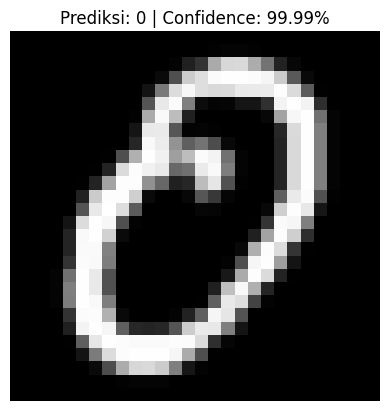

Probabilitas tiap kelas: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [17]:
def predict_digit(image_28x28, model=final_model):
    arr = np.asarray(image_28x28).astype(np.float32)
    if arr.shape != (28, 28):
        raise ValueError("Input harus berukuran 28 x 28 piksel.")
    if arr.max() > 1.0:
        arr = arr / 255.0

    x = torch.tensor(arr.reshape(1, 784), dtype=torch.float32).to(DEVICE)
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probabilities = torch.softmax(logits, dim=1)[0]
        pred = int(torch.argmax(probabilities).item())
        confidence = float(probabilities[pred].item())
    return pred, confidence, probabilities.cpu().numpy()

# Uji fungsi dengan salah satu gambar dari data uji.
sample_image = X_test[0].reshape(28, 28)
pred, confidence, probabilities = predict_digit(sample_image)
plt.imshow(sample_image, cmap="gray")
plt.axis("off")
plt.title(f"Prediksi: {pred} | Confidence: {confidence:.2%}")
plt.show()
print("Probabilitas tiap kelas:", np.round(probabilities, 3))

### 12.1 Unggah dan Prediksi Gambar Kustom Anda sendiri
Jalankan sel di bawah ini untuk mengunggah berkas gambar (PNG/JPG) dari komputer Anda.

Saving WhatsApp Image 2026-11-17 at 21.12.17.jpeg to WhatsApp Image 2026-11-17 at 21.12.17.jpeg


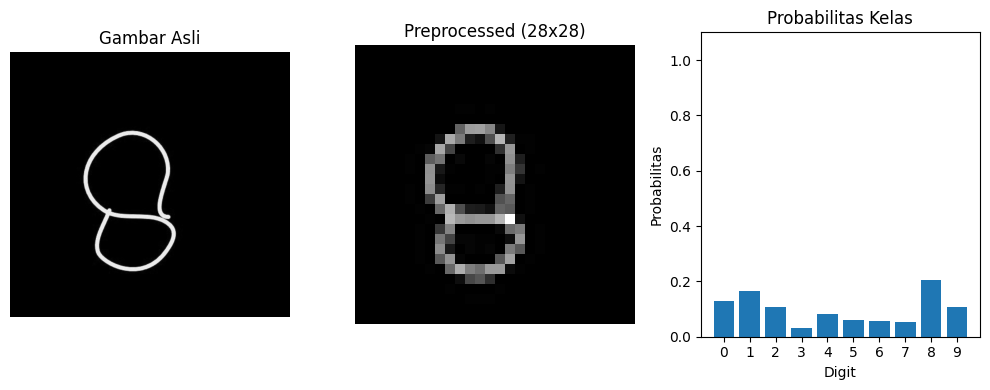


Hasil Prediksi untuk file 'WhatsApp Image 2026-11-17 at 21.12.17.jpeg':
-> Digit Terdeteksi: 8
-> Tingkat Keyakinan (Confidence): 20.63%


In [19]:
from google.colab import files
from PIL import Image, ImageOps
import io

uploaded = files.upload()

for filename in uploaded.keys():
    # Memuat gambar
    img_bytes = uploaded[filename]
    img = Image.open(io.BytesIO(img_bytes)).convert('L') # Ubah ke Grayscale

    # Tampilkan gambar asli yang diunggah
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Gambar Asli")
    plt.axis('off')

    # Preprocessing agar sesuai dengan format EMNIST (latar belakang hitam, goresan putih)
    # Kita asumsikan jika latar belakang gambar mayoritas putih, kita balik (invert) warnanya.
    img_np = np.array(img)
    if img_np.mean() > 127:
        img = ImageOps.invert(img)

    # Resize ke 28x28 piksel
    img_resized = img.resize((28, 28), Image.Resampling.LANCZOS)
    img_resized_np = np.array(img_resized)

    # Tampilkan gambar hasil preprocessing
    plt.subplot(1, 3, 2)
    plt.imshow(img_resized, cmap='gray')
    plt.title("Preprocessed (28x28)")
    plt.axis('off')

    # Prediksi menggunakan model
    pred, confidence, probabilities = predict_digit(img_resized_np)

    # Visualisasi probabilitas
    plt.subplot(1, 3, 3)
    classes = [str(i) for i in range(10)]
    plt.bar(classes, probabilities)
    plt.title("Probabilitas Kelas")
    plt.xlabel("Digit")
    plt.ylabel("Probabilitas")
    plt.ylim(0, 1.1)

    plt.tight_layout()
    plt.show()

    print(f"\nHasil Prediksi untuk file '{filename}':")
    print(f"-> Digit Terdeteksi: {pred}")
    print(f"-> Tingkat Keyakinan (Confidence): {confidence:.2%}")

## 13. Menyimpan model dan hasil eksperimen

In [18]:
# Simpan bobot model PyTorch dan metrik evaluasi.
torch.save({
    "model_state_dict": final_model.state_dict(),
    "input_size": INPUT_SIZE,
    "num_classes": NUM_CLASSES,
    "architecture": "784-256-128-10",
    "orientation_fixed": FIX_EMNIST_ORIENTATION
}, "emnist_mlp_digits.pth")

test_metrics_df.to_csv("emnist_mlp_test_metrics.csv", index=False)
cv_results.to_csv("emnist_mlp_cv_results.csv", index=False)

print("File tersimpan:")
print("- emnist_mlp_digits.pth")
print("- emnist_mlp_test_metrics.csv")
print("- emnist_mlp_cv_results.csv")

File tersimpan:
- emnist_mlp_digits.pth
- emnist_mlp_test_metrics.csv
- emnist_mlp_cv_results.csv
